# Part A — Beam-matched ring TODs

**Origin:** `notebooks/18_beam_matched_tods.ipynb` (archived: `../moonrunes_archive_2026-11-16/notebooks/18_beam_matched_tods.ipynb`)

| | |
|---|---|
| **Reads** | `paper_outputs/pipeline/step2_ring_tods/` (`beam_matched_tods.npz`, made by `run_pipeline.py --step ring_tods`), `test_outputs/beam_matched_vs_old/old_native_tods.npz` |
| **Writes** | `test_outputs/beam_matched_vs_old/` (`beam_matched_minus_old.csv`, figure) |
| **Feeds the paper** | nothing directly (the TODs it reads feed fig4 and fig8) |

**Stored outputs** are from the original notebook (not re-run after the merge). The cache is reused when its key matches the config (`REBUILD = False`).

**Pipeline:** the TODs come from pipeline step 2 (`moonrunes.pipeline.step_ring_tods`); this Part reads them and compares them with the old TODs.

## Beam-matched ring TODs for every survey and sky model

**Why.** The older route (`sed.tod_beam: native`, `sed_prototype.Inputs._native_tod`) makes a TRIS ring TOD from the map at its
**own resolution**, degraded to nside 16 and observed with limTOD's measured TRIS beam on an nside-16 grid. That is a
convolution with the TRIS beam, but **not beam matching**: each survey's own beam (LWA1 35 MHz 4.65°, Maipu 4.6°,
LWA1 80 MHz 2.04°, LFSM 5.1°, …) stays in the TOD on top of the TRIS beam, and the sky is pixelised at nside 16
(3.7° pixels) before the beam is applied. The TRIS data themselves see the sky through the TRIS beam only.

**What this notebook does.** It makes ring TODs with the **pipeline's own beam matching**: stage 2's `tris_cuts`
kernel (`moonrunes.elliptical_beam`, `PIPELINE.md` Appendix A.9), evaluated directly at the 120 ring pointings.

* **Kernel:** the measured TRIS cut beam (19.155° × 23.366°, E plane 7° east of the meridian, zero beyond 90°).
  For a survey whose own beam would widen the TRIS core by more than 0.2% (natives above ~1.2°), the cut beam is
  compressed to the quadrature widths √(TRIS² − native²), so that after the survey's own beam the total is the TRIS
  beam (`broad_native_kernel: scaled_cuts`). Narrower natives use the cut beam as is.
* **Pointings:** TRIS is a zenith-pointing drift scan, so ring sample k sees RA = LST_k, Dec = 42.433° (limTOD's
  `tris_zenith_geometry`).
* **Sky grid:** the map is put on nside 64 (0.92° pixels, `beam_matching.elliptical.nside_work`), 4× finer than the
  old TOD route; partial maps use the normalised convolution, and a sample is kept when the observed-weight fraction
  is ≥ 0.5 (`beam_matching.weight_floor`), the same floor as the old coverage cut.
* **Maps:** every fitted survey and Haslam at their own frequency; the seven 408 MHz sky models of notebook 12; and
  GSM2008 and GSM2016 at the TRIS effective frequencies (600.5, 817.8 MHz).
* **Corrections stretched to the TRIS frequencies:** the Carter and Irfan corrections are defined at 408 MHz and GINAN
  at 350 MHz, so they cannot be applied at 600/820 MHz directly. Each is applied to the base model's 408 MHz map
  (GSM2008 or GSM2016; GINAN to GSM2016 as in notebook 12), and the corrected map is carried to 600.5 / 817.8 MHz
  with the base model's own per-pixel spectrum: T_corr(ν) = T_corr(408) × T_model(ν) / T_model(408). This keeps
  each model's spectral shape and scales the correction with it; it is an assumption, not part of the published
  corrections. Applying Carter (a Haslam calibration) to GSM2008 is natural because GSM2008 is locked to Haslam at
  408 MHz; for GSM2016 it is a test of the same idea.
* **LFSM stretched to the TRIS frequencies:** LFSM is only valid up to 408 MHz and has no spectrum above it, so it is
  extended as a power law with its own per-pixel spectral index between 300 and 408 MHz:
  T(ν) = T(408) (ν/408)^β, β = ln[T(408)/T(300)] / ln(408/300). Also an assumption. Temperatures are converted exactly as for
  the SED fit (`sky_maps.rj_excess`: RJ, CMB removed).

**Outputs** go to `paper_outputs/beam_matched_tods/`: the TODs (`beam_matched_tods.npz` and a CSV), the native
beams used, and a comparison with the old TODs. Notebooks 14 (T–T and TRIS-frequency TODs) read them.
**Used everywhere:** `sed_prototype.Inputs.ring_tod` makes exactly these TODs
(`run_pipeline.yaml` `sed.tod_beam: beam_matched`; equal to the cache here to 0 K), so the pipeline and the SED fits
(`run_comparison.py`) use them. The old TODs this
notebook compares against are kept in `old_native_tods.npz`.

Rerun: Restart & Run All (a few minutes; the result is cached).

In [1]:
%matplotlib inline
import time as _nb_time; _NB_T0 = _nb_time.time()   # notebook run time, printed by the last cell
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "run_pipeline.yaml").exists())
OUT_DIR = REPO / "test_outputs" / "beam_matched_vs_old"          # this Part's comparison with the old TODs
PIPE2 = REPO / "paper_outputs" / "pipeline" / "step2_ring_tods"  # run_pipeline.py step 2 makes the TODs; read only
OLD_SNAPSHOT = OUT_DIR / "old_native_tods.npz"                    # the old TODs, saved 2026-10-27
CYG_A_RA = 299.9

sys.path.insert(0, str(REPO / "src"))
from moonrunes.style import use_tris_style, COLORS
use_tris_style()
plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12,
                     "legend.fontsize": 10, "figure.facecolor": "white"})
OUT_DIR.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png")
    plt.show()
    print(f"saved {(OUT_DIR / f'{name}.png').relative_to(REPO)}")

### The beam-matched observation

`ring_tod(sky, observed, frame, native_fwhm)` rotates a map to equatorial (as `Inputs._rotated` does), and evaluates
the pipeline's beam-matching kernel for that native beam at the 120 ring pointings. The table lists the kernel chosen
for each native width.

In [2]:
sys.dont_write_bytecode = True
sys.path.insert(0, str(REPO / "src"))
import healpy as hp
from moonrunes import frames, sky_maps, elliptical_beam
from moonrunes.config import load_config
from moonrunes.stage1_tris_maps import import_limtod_tris

config = load_config(REPO / "configs" / "run_pipeline.yaml")
SPEC = elliptical_beam.beam_spec_from_config(config, kernel="tris_cuts")
FLOOR = float(config.require("beam_matching.weight_floor"))
tris = import_limtod_tris(config)
RA = np.load(PIPE2 / "beam_matched_tods.npz")["ra_deg"]
geom = tris.tris_zenith_geometry(RA)
assert np.allclose(geom.elevation_deg, 90.0) and np.allclose(geom.lst_deg, RA)
DEC = float(geom.latitude_deg)
VEC = hp.ang2vec(np.radians(90.0 - DEC) * np.ones_like(RA), np.radians(RA))
print(f"{RA.size} pointings at Dec {DEC:.3f} deg, RA = LST 0-357 deg; kernel spec: tris_cuts, "
      f"E {SPEC.fwhm_e_deg} x H {SPEC.fwhm_h_deg} deg, nside_work {SPEC.nside_work}, weight floor {FLOOR}")


rows = []
for n in sorted({0.24, 0.33, 0.59, 0.8, 0.933, 1.0, 2.04, 4.6, 4.65, 5.1}):
    k = elliptical_beam.kernel_for(SPEC, n)
    rows.append({"native FWHM [deg]": n, "kernel": k.shape, "kernel E x H [deg]": f"{k.fwhm_e_deg:.2f} x {k.fwhm_h_deg:.2f}",
                 "expected total E x H [deg]": f"{k.expected_e_deg:.2f} x {k.expected_h_deg:.2f}"})
print(pd.DataFrame(rows).to_string(index=False))

120 pointings at Dec 42.433 deg, RA = LST 0-357 deg; kernel spec: tris_cuts, E 19.155 x H 23.366 deg, nside_work 64, weight floor 0.5
 native FWHM [deg]    kernel kernel E x H [deg] expected total E x H [deg]
             0.240 tris_cuts      19.16 x 23.37              19.16 x 23.37
             0.330 tris_cuts      19.16 x 23.37              19.16 x 23.37
             0.590 tris_cuts      19.16 x 23.37              19.16 x 23.37
             0.800 tris_cuts      19.16 x 23.37              19.17 x 23.38
             0.933 tris_cuts      19.16 x 23.37              19.18 x 23.38
             1.000 tris_cuts      19.16 x 23.37              19.18 x 23.39
             2.040 tris_cuts      19.05 x 23.28              19.16 x 23.37
             4.600 tris_cuts      18.59 x 22.91              19.16 x 23.37
             4.650 tris_cuts      18.58 x 22.90              19.16 x 23.37
             5.100 tris_cuts      18.46 x 22.80              19.16 x 23.37


### Build the TODs (cached)

In [3]:
# The beam-matched ring TODs of every survey and sky model are made by the pipeline
# (`python run_pipeline.py --step ring_tods`, step 2; code in moonrunes.pipeline.step_ring_tods); this Part reads them.
CACHE = PIPE2 / "beam_matched_tods.npz"
if not CACHE.exists():
    raise FileNotFoundError(f"{CACHE.relative_to(REPO)} is missing: run `python run_pipeline.py --step ring_tods` first")
z = np.load(CACHE, allow_pickle=False)
BM = {k: z[k] for k in z.files}
META = pd.read_csv(PIPE2 / "beam_matched_tods_meta.csv")
print(f"beam-matched TODs read from {CACHE.relative_to(REPO)}")
print(META.round(3).to_string(index=False))

beam-matched TODs read from paper_outputs/pipeline/step2_ring_tods/beam_matched_tods.npz
          kind                        name  freq_mhz  native_fwhm_deg    kernel  kernel_e_deg  kernel_h_deg  n_valid
        survey              LWA_35MHz.fits      35.0            4.650 tris_cuts        18.582        22.899      120
        survey                LWA1_38.fits      38.0            4.280 tris_cuts        18.671        22.971      120
        survey                LWA1_40.fits      40.0            4.070 tris_cuts        18.718        23.009      120
        survey                LWA1_45.fits      45.0            3.620 tris_cuts        18.810        23.084      120
        survey            MAIPU_45mhZ.fits      45.0            4.600 tris_cuts        18.594        22.909      120
        survey                LWA1_50.fits      50.0            3.260 tris_cuts        18.876        23.137      120
        survey                LWA1_60.fits      60.0            2.710 tris_cuts        18.96

### How much does beam matching change the TODs?

The beam-matched TOD minus the old TOD (`Inputs._native_tod`), in kelvin, per ring sample: the median, the median of
the absolute value and the largest absolute value. The old TODs are the fit inputs of notebook 12's power-law fits,
its 408 MHz sky-model TODs and notebook 14's GSM TODs at the TRIS frequencies, as they were before the switch; they
were saved to `old_native_tods.npz` on 2026-10-27, because rerunning notebooks 12 and 14 replaces those caches.

In [4]:
# The old TODs, as notebook 12's fit cache, its sky_tods.npz and notebook 14's GSM cache held them before
# the switch (rerunning those notebooks replaces them with the beam-matched ones).
zo = np.load(OLD_SNAPSHOT, allow_pickle=False)
assert np.allclose(zo["ra_deg"], RA)
old = {k: zo[k] for k in zo.files if k != "ra_deg"}

NATIVE_OF = META.groupby("name")["native_fwhm_deg"].first().to_dict()
rows = []
for k in [k for k in BM if not k.startswith("weight::") and k != "ra_deg"]:
    if k not in old:
        continue
    d = BM[k] - old[k]
    ok = np.isfinite(d)
    rows.append({"TOD": k.split("::", 1)[1].replace("::", " at "), "kind": k.split("::")[0],
                 "native FWHM [deg]": float(NATIVE_OF[k.split("::")[1]]),
                 "N": int(ok.sum()), "median new − old [K]": np.median(d[ok]),
                 "median |new − old| [K]": np.median(np.abs(d[ok])), "largest |new − old| [K]": np.abs(d[ok]).max(),
                 "RA of largest [deg]": RA[ok][np.argmax(np.abs(d[ok]))]})
CMP = pd.DataFrame(rows)
CMP.to_csv(OUT_DIR / "beam_matched_minus_old.csv", index=False)
with pd.option_context("display.width", 220):
    print(CMP.round(3).to_string(index=False))

                        TOD      kind  native FWHM [deg]   N  median new − old [K]  median |new − old| [K]  largest |new − old| [K]  RA of largest [deg]
             LWA_35MHz.fits    survey              4.650 120               -30.169                  41.927                  263.759               302.75
           MAIPU_45mhZ.fits    survey              4.600 120               -17.256                  23.701                  105.259               302.75
             LWA_80MHz.fits    survey              2.040 120                -1.926                   2.290                   18.304               302.75
STOCKERT_VILLA_1400MHZ.fits    survey              0.590 120                -0.000                   0.001                    0.010               305.75
 HASLAM_DESTRIPED_ONLY.fits    survey              0.933 120                -0.018                   0.021                    0.237               300.00
       Haslam (uncorrected)  model408              0.933 120                -0.018

#### Figure 1 — beam-matched minus old TOD along the ring
Each line is one TOD: the beam-matched ring TOD minus the old one, in kelvin. Left: the surveys used in the SED fit
and Haslam; right: the 408 MHz sky models. The dotted line is Cygnus A.

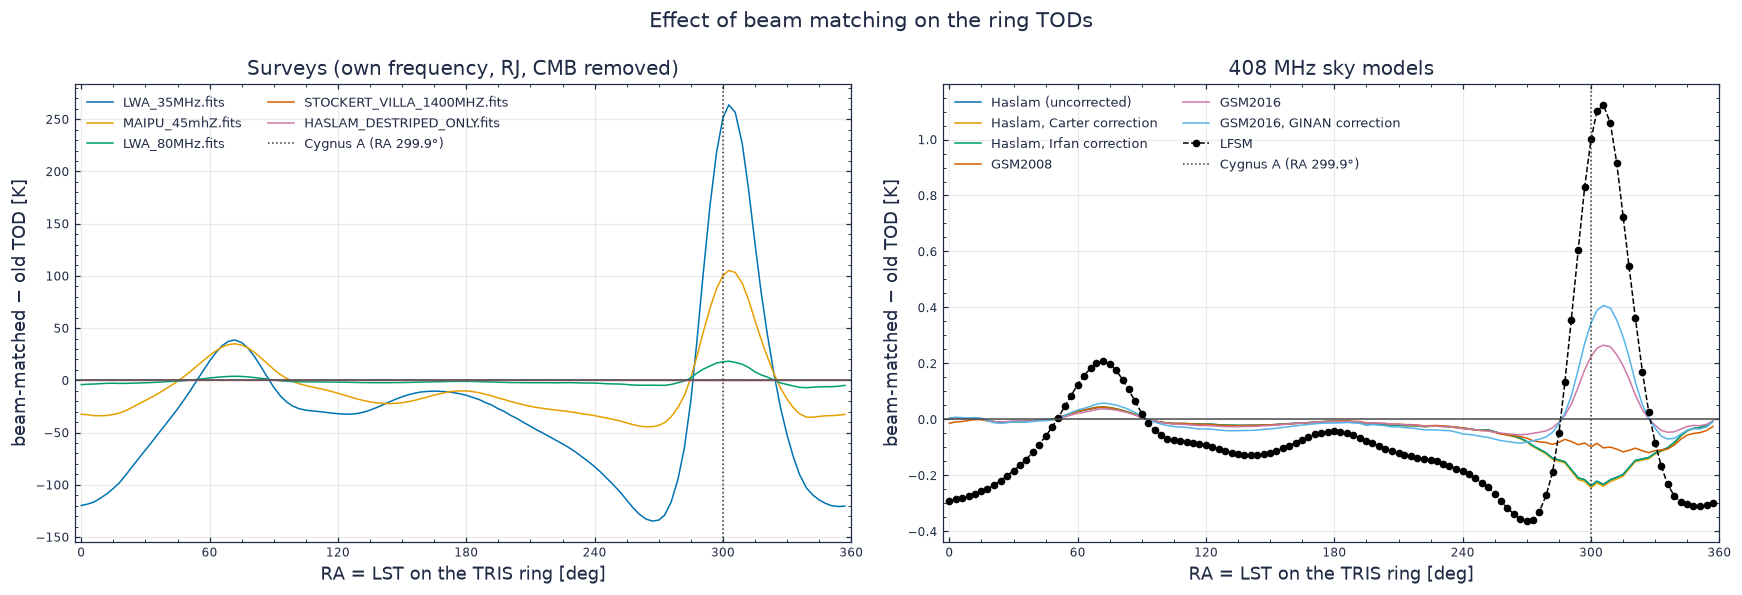

saved test_outputs/beam_matched_vs_old/fig1_beam_matched_minus_old.png


In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 5.5), sharex=True)
cols = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#000000", "#882255"]
for ax, kind in ((a1, "survey"), (a2, "model408")):
    keys = [k for k in BM if k.startswith(kind + "::") and k in old]
    for c, k in zip(cols, keys):
        ax.plot(RA, BM[k] - old[k], color=c, label=k.split("::")[1])
    ax.axhline(0, color="0.3")
    ax.axvline(CYG_A_RA, color="0.2", ls=":", label=f"Cygnus A (RA {CYG_A_RA:g}°)")
    ax.set_xlim(-3, 360); ax.set_xticks(np.arange(0, 361, 60)); ax.grid(alpha=0.25)
    ax.set_xlabel("RA = LST on the TRIS ring [deg]"); ax.set_ylabel("beam-matched − old TOD [K]")
    ax.legend(fontsize=8.5, ncol=2)
a1.set_title("Surveys (own frequency, RJ, CMB removed)"); a2.set_title("408 MHz sky models")
fig.suptitle("Effect of beam matching on the ring TODs", fontsize=14)
fig.tight_layout()
save(fig, "fig1_beam_matched_minus_old")

### Where the beam-matched TODs are used

The pipeline's own TOD code makes these TODs: `sed_prototype.Inputs.ring_tod`, set by
`run_pipeline.yaml` `sed.tod_beam: beam_matched` (the older route is `sed.tod_beam: native`). Its TODs equal this
notebook's cache to 0 K, with the same valid samples, for every survey and Haslam.

* **Read from this notebook's cache:** notebook 14 (T–T β, the β matrix and the TRIS-frequency TODs).
* **Made by `Inputs.ring_tod`:** the SED fits behind `paper_outputs/model_comparison/results/` (`run_comparison.py`), notebook 12's
  fit cache and 408 MHz sky-model TODs (and so notebooks 13, 15, 16 and 17, which read them), notebook 11, and notebooks
  07, 08 and 10. Their caches carry a `tod_key`, so fits made from the old TODs are redone, not reused.
* **Not changed:** notebooks 01, 03, 09 and `beam_averaging_blobs/`, which study the TRIS beam itself with limTOD, and
  the map route and stage 2, which smooth with `beam_matching.kernel`.


In [ ]:
# Total notebook run time: from the first code cell (which sets _NB_T0) to here.
import time as _nb_time
if "_NB_T0" in globals():
    _dt = _nb_time.time() - _NB_T0
    print(f"total notebook run time: {_dt:.0f} s ({int(_dt // 3600)}h {int(_dt % 3600 // 60):02d}m {int(_dt % 60):02d}s)")
else:
    print("total notebook run time: not recorded (the first code cell was not run)")